# Barnstable and Long-Run Risk

## HBS Case

### *The Risk of Stocks in the Long-Run: The Barnstable College Endowment*

***

# Case Study: Estimating Underperformance

### Data

Use the returns on the S&P 500 ($r^m$) and 1-month T-bills, ($r^f$) provided in `barnstable_analysis_data.xlsx`.
* Data goes through `END_YR=2025`.

Barnstable's estimates of mean and volatility are based on the subsample of 1965 to 1999.
* We consider this subsample, as well as 2000-{END_YR}, as well as the full sample of 1926-{END_YR}.

### Notation

* $r$ = level return rates
* $R$ = cumulative return factor
* $\texttt{r}$ = log return rates

$$ R \equiv 1+r$$

$$ \texttt{r} \equiv \ln(1+r) = \ln(R)$$

### 1. Summary Statistics

Report the following (annualized) statistics.

| | 1965-1999 | | | 2000-2025 | | | 1926-2025 | |
|---|---|---|---|---|---|---|---|---|
| | mean | vol | | mean | vol | | mean | vol |
| **levels** | $r^m$ | | | | | | | |
| | $\tilde{r}^m$ | | | | | | | |
| | $r^f$ | | | | | | | |
| **logs** | $\texttt{r}^m$ | | | | | | | |
| | $\tilde{\texttt{r}}^m$ | | | | | | | |
| | $\texttt{r}_f$ | | | | | | | |

* Comment on how the full-sample return stats compare to the sub-sample stats.
* Comment on how the level stats compare to the log stats.

In [19]:
import pandas as pd
import numpy as np
path = "data/barnstable_analysis_data.xlsx"
barnstable = pd.read_excel(path, sheet_name="data")
barnstable['date'] = pd.to_datetime(barnstable['date'])

barnstable['rf'] = barnstable['TB1M']
barnstable['rm'] = barnstable['SPX']
barnstable['rm excess'] = barnstable['rm'] - barnstable['rf']
barnstable['log rf'] = np.log1p(barnstable['rf'])
barnstable['log rm'] = np.log1p(barnstable['rm'])
barnstable['log rm excess'] = np.log1p(barnstable['rm excess'])

sub_sample1 = barnstable[(barnstable['date'].dt.year >= 1965) & (barnstable['date'].dt.year <= 1999)]
sub_sample2 = barnstable[(barnstable['date'].dt.year >= 2000) & (barnstable['date'].dt.year <= 2025)]
full_sample = barnstable[(barnstable['date'].dt.year >= 1926) & (barnstable['date'].dt.year <= 2025)]

relevant_cols = ['rm excess', 'log rm excess', 'rf', 'log rf','rm', 'log rm']
#annualize mean
#helper 
summary = pd.DataFrame({
    ('1965-1999', 'mean'): sub_sample1[relevant_cols].mean() * 12,
    ('1965-1999', 'vol'): sub_sample1[relevant_cols].std() * np.sqrt(12),
    ('2000-2025', 'mean'): sub_sample2[relevant_cols].mean() * 12,
    ('2000-2025', 'vol'): sub_sample2[relevant_cols].std() * np.sqrt(12),
    ('1926-2025', 'mean'): full_sample[relevant_cols].mean() * 12,
    ('1926-2025', 'vol'): full_sample[relevant_cols].std() * np.sqrt(12),
})
print(summary)

              1965-1999           2000-2025           1926-2025          
                   mean       vol      mean       vol      mean       vol
rm excess      0.067873  0.150120  0.072555  0.151621  0.084272  0.186322
log rm excess  0.056395  0.151095  0.060819  0.152729  0.066817  0.185900
rf             0.061482  0.007172  0.018269  0.005573  0.031831  0.008446
log rf         0.061299  0.007125  0.018240  0.005562  0.031753  0.008412
rm             0.129354  0.149405  0.090824  0.151383  0.116102  0.186030
log rm         0.117600  0.149568  0.079031  0.152302  0.098503  0.185323


Comparing the 2 subsamples versus the full sample, I see that the market return falls from 0.129 to 0.09 after 1999, but excess return doesn't decrease much which tells me that the T-bill rates coallapsed as evident in the change in mean from 0.061 to 0.018 for "rf" row. Volatility across these subsamples are pretty similar, however the excess return and volatility for excess returns for the full sample are higher than both subsamples. This indicates that it is likely that excess returns were higher before 1965 which isn't captured in the subsamples. 

Comparing the log level to regular level, log mean returns are consitently lower than regular level means (by about 1.2% in subsample and 1.8% in full sample). The difference is larger in the full sample because that is the more volatile range compared to the 2 subsamples.

### 2. Probability of Underperformance

Recall the following:
- If $x\sim\mathcal{N}\left(\mu_x,\sigma_x^2\right)$, then

  $$\Pr\left[x<\ell\right] = \Phi_\mathcal{N}\left(L\right)$$

  where $L = \frac{\ell-\mu_x}{\sigma_x}$ and $\Phi_\mathcal{N}$ denotes the standard normal cdf.

- Remember that cumulative log returns are simply the sum of the single-period log returns:
  
  $$\texttt{r}^m_{t,t+h} \equiv \sum_{i=1}^h \texttt{r}^m_{t+i}$$

- It will be convenient to use and denote sample averages. We use the following notation for an $h$-period average ending at time $t+h$:
  
  $$\bar{\texttt{r}}^m_{t,t+h} = \frac{1}{h}\sum_{i=1}^h \texttt{r}^m_{t+i}$$

Calculate the probability that the cumulative market return will fall short of the cumulative risk-free return:

$$\Pr\left[R^m_{t,t+h} < R^f_{t,t+h}\right]$$

To analyze this analytically, convert the probability statement above to a probability statement about mean log returns.

#### 2.1
Calculate the probability using the subsample 1965-1999.

In [ ]:
from scipy.stats import norm
def calc_prob(h):
    mu = summary.loc['log rm excess', ('1965-1999', 'mean')]
    sd = summary.loc['log rm excess', ('1965-1999', 'vol')]
    L = (np.sqrt(h) *(0 - mu)) / sd
    return norm.cdf(L)




#### 2.2
Report the precise probability for $h=15$ and $h=30$ years.

In [14]:
for h in (15,30):
    print(f"probability for h = {h}: {calc_prob(h)}")

probability for h = 15: 2.423205921202563e-41
probability for h = 30: 1.4078421523096542e-80



#### 2.3
Plot the probability as a function of the investment horizon, $h$, for $0<h\le 30$ years.

**Hint**: The probability can be expressed as:

$$p(h) = \Phi_{\mathcal{N}}\left(-\sqrt{h}\;\text{SR}\right)$$

where $\text{SR}$ denotes the sample Sharpe ratio of **log** market returns.

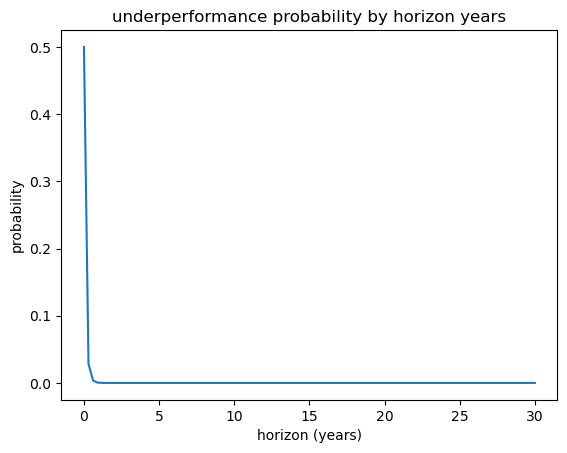

In [15]:
import matplotlib.pyplot as plt
h = np.linspace(0, 30, 100)
plt.plot(h, calc_prob(h))
plt.xlabel("horizon (years)")
plt.ylabel("probability")
plt.title("underperformance probability by horizon years")
plt.show()

### 3. Full Sample Analysis

Use the sample 1965-{END_YR} to reconsider the 30-year probability. As of the end of {END_YR}, calculate the probability of the stock return underperforming the risk-free rate over the next 30 years. That is, $R^m_{t,t+h}$ underperforming $R^f_{t,t+h}$ for $0<h\le 30$.

In [27]:
sample_65to25 = barnstable[(barnstable['date'].dt.year >= 1965) & (barnstable['date'].dt.year <= 2025)]

def calc_prob_65to25(h):
    mu_65to25 = sample_65to25['log rm excess'].mean() * 12
    sd_65to25 = sample_65to25['log rm excess'].std() * np.sqrt(12)
    L = (np.sqrt(h) *(0 - mu_65to25)) / sd_65to25
    return norm.cdf(L)



In [31]:
for h in [1, 5, 10, 15, 30]:
    print(f"h = {h}: {calc_prob_65to25(h)}")

h = 1: 0.3504132459359178
h = 5: 0.19514031248944247
h = 10: 0.1121901060724056
h = 15: 0.06837285242672812
h = 30: 0.017672760624666176


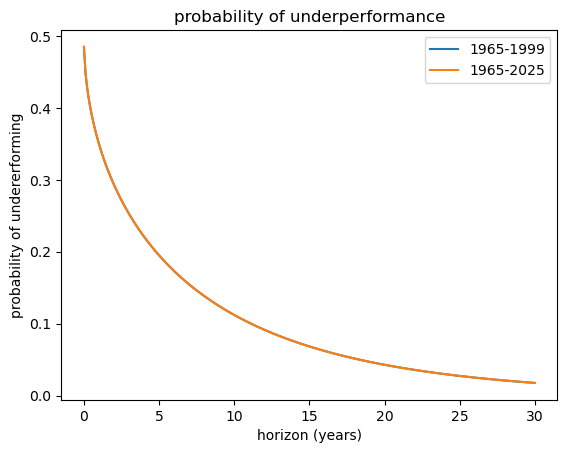

In [32]:
# Plot for 0 < h <= 30, with the 1965-1999 curve for comparison
h = np.linspace(0.01, 30, 300)
plt.plot(h, calc_prob_65to25(h), label='1965-1999')
plt.plot(h, calc_prob_65to25(h), label='1965-2025')
plt.xlabel('horizon (years)')
plt.ylabel('probability of undererforming')
plt.title('probability of underperformance')
plt.legend()
plt.show()

### 4. In-Sample Estimate of Out-of-Sample Likelihood

Let's consider how things turned out relative to Barnstable's 1999 expectations.

What was the probability (based on the 1999 estimate of $\mu$) that the `h`-year market return, $R^m_{t,t+h}$, would be smaller than that realized in `2000-{END_YR}`? 

**Hint**: You can calculate this as:

$$p = \Phi_{\mathcal{N}}\left(\sqrt{h}\; \frac{\bar{\texttt{r}}_{out-of-sample} - \bar{\texttt{r}}_{\text{in-sample}}}{\sigma_{\text{in-sample}}}\right)$$

where "in-sample" denotes 1965-1999 and "out-of-sample" denotes 2000-{END_YR}.

***

# Exercise: Decomposing Private Equity

Use the data in `../data/private_equity_data.xlsx`

In [1]:
import pandas as pd

In [2]:
LOADFILE = 'data/private_equity_data.xlsx'
info = pd.read_excel(LOADFILE,sheet_name='descriptions').set_index('ticker')
rets = pd.read_excel(LOADFILE,sheet_name='total returns').set_index('date')

In [3]:
info

,shortName,quoteType,currency,volume,totalAssets,longBusinessSummary
ticker,,,,,,
SPY,SPDR S&P 500,ETF,USD,65058380,6.727266e+11,The trust seeks to achieve its investment obje...
VTV,Vanguard Value ETF,ETF,USD,2008018,2.069965e+11,The manager employs an indexing investment app...
AGG,iShares Core U.S. Aggregate Bon,ETF,USD,5268591,1.318272e+11,The index measures the performance of the tota...
HYG,iShares iBoxx $ High Yield Corp,ETF,USD,35079406,1.854291e+10,The underlying index is a rules-based index co...
IEF,iShares 7-10 Year Treasury Bond,ETF,USD,5154346,3.851085e+10,The underlying index measures the performance ...
PSP,Invesco Global Listed Private E,ETF,USD,46427,3.347804e+08,The fund generally will invest at least 90% of...
PEX,ProShares Global Listed Private,ETF,USD,4331,1.390970e+07,The fund invests in financial instruments that...
APO,"Apollo Global Management, Inc.",EQUITY,USD,3430863,NaN,"Apollo Global Management, Inc. is a private eq..."
BX,Blackstone Inc.,EQUITY,USD,3218280,NaN,Blackstone Inc. is an alternative asset manage...


In [4]:
display(rets.head().style.format('{:.1%}').format_index('{:%Y-%m-%d}'))
display(rets.tail().style.format('{:.1%}').format_index('{:%Y-%m-%d}'))

,SPY,VTV,AGG,HYG,IEF,PSP,PEX,APO,BX,KKR,CG,SHV
date,,,,,,,,,,,,
2015-01-09,-0.6%,-0.7%,0.5%,0.6%,1.4%,-0.7%,-0.6%,1.3%,0.2%,1.1%,-5.7%,0.0%
2015-01-16,-1.3%,-1.2%,0.4%,-0.6%,1.0%,-1.4%,-1.1%,0.3%,-1.6%,-3.3%,-6.4%,0.0%
2015-01-23,1.7%,1.2%,0.2%,0.5%,0.2%,2.0%,0.9%,2.8%,7.1%,5.7%,3.2%,0.0%
2015-01-30,-2.7%,-3.4%,0.6%,0.2%,1.2%,-0.1%,0.9%,1.0%,3.5%,-1.0%,2.5%,-0.0%
2015-02-06,3.1%,3.8%,-1.2%,0.8%,-2.4%,2.7%,2.9%,-2.3%,-3.4%,3.0%,1.2%,0.0%


,SPY,VTV,AGG,HYG,IEF,PSP,PEX,APO,BX,KKR,CG,SHV
date,,,,,,,,,,,,
2025-09-05,0.3%,-0.4%,0.6%,0.0%,0.7%,-1.3%,-0.7%,-3.4%,-0.8%,-2.8%,-1.3%,-0.2%
2025-09-12,1.6%,1.3%,0.4%,0.1%,0.2%,1.9%,-0.1%,4.9%,6.7%,5.8%,4.5%,0.1%
2025-09-19,1.0%,0.4%,-0.2%,0.4%,-0.4%,0.3%,-1.2%,4.9%,3.5%,3.9%,2.4%,0.1%
2025-09-26,-0.3%,0.5%,-0.2%,-0.2%,-0.4%,-3.8%,-4.9%,-4.9%,-6.6%,-10.0%,-6.1%,0.1%
2025-10-03,0.3%,-0.4%,0.2%,0.2%,0.3%,0.4%,0.2%,0.6%,0.5%,0.4%,1.4%,0.0%


# 1. Performance

Calculate performance stats for the assets, both stand-alone (mean, vol, Sharpe) as well as linear decompositions (alpha, beta, info ratio, r-squared).

# 2. Replication

Can we replicate private equity `APO` using the following?
* public equity `SPY`
* treasury bonds `IEF`
* high-yield corp bonds `HYG`

How does that compare to `APO` against `SPY` alone?

***

# Exercise: VaR of Equity Portfolio

## Data

This problem uses `weekly` return data from `data/spx_returns_weekly.xlsx`.

Choose any `4` stocks to evaluate below.

For example, 
* `AAPL`
* `META`
* `NVDA`
* `TSLA`

# 1 Diversification

## 1.1

Using the full sample, calculate for each series the (unconditional) 
* volatility
* empirical VaR (.05)
* empirical CVaR (.05)

Recall that by **empirical** we refer to the direct quantile estimation. (For example, using `.quantile()` in pandas.

## 1.2
Form an equally-weighted portfolio of the investments.

Calculate the statistics of `1.1` for this portfolio, and compare the results to the individual return statistics. What do you find? What is driving this result?

## 1.3
Re-calculate `1.2`, but this time drop your most volatile asset, and replace the portion it was getting with 0. (You could imagine we're replacing the most volatile asset with a negligibly small risk-free rate.)

In comparing the answer here to 1.2, how much risk is your most volatile asset adding to the portfolio? Is this in line with the amount of risk we measured in the stand-alone risk-assessment of `1.1`?

***

# 2. Dynamic Measures

## 2.1 

Let's measure the **conditional** statistics of the equally-weighted portfolio of `1.2`, as of the end of the sample.

#### Volatility
For each security, calculate the **rolling** volatility series, $\sigma_t$, with a window of $m=26$.

The value at $\sigma_t$ in the notes denotes the estimate using data through time $t-1$, and thus (potentially) predicting the volatility at $\sigma_{t}$. 

#### Mean
Suppose we can approximate that the weekly mean return is zero.

#### VaR
Calculate the **normal VaR** and **normal CVaR** for $q=.05$ and $\tau=1$ as of the end of the sample. Use the approximation, $\texttt{z}_{.05} = -1.65$.

#### Notation Note
In this setup, we are using a forecasted volatility, $\sigma_t$ to estimate the VaR return we would have estimated at the end of $t-1$ in prediction of time $t$.

#### Conclude and Compare
Report
* volatility (annualized).
* normal VaR (.05)
* normal CVaR (.05)

How do these compare to the answers in `1.2`?

## 2.2

Backtest the VaR using the **hit test**. Namely, check how many times the realized return at $t$ was smaller than the VaR return calculated using $\sigma_t$, (where again remember the notation in the notes uses $\sigma_t$ as a vol based on data through $t-1$.)

Report the percentage of "hits" using both the 
* expanding volatility
* rolling volatility

***